# Diagnóstico exploratório dos dados de crédito

## Contexto e leitura da base

Neste notebook, vamos investigar a base bruta da competição **Give Me Some Credit** e registrar evidências para orientar as decisões de limpeza e os testes de qualidade.

A análise começa com três perguntas.

1. Quantos registros e colunas a base contém?
2. Como se distribui a variável-alvo `SeriousDlqin2yrs`?
3. Quais colunas têm valores ausentes e com que frequência?

In [1]:
from pathlib import Path

import pandas as pd

pasta_projeto = Path.cwd()
if pasta_projeto.name == "notebooks":
    pasta_projeto = pasta_projeto.parent

caminho_csv = pasta_projeto / "data" / "raw" / "cs-training.csv"
df = pd.read_csv(caminho_csv)

linhas, colunas = df.shape
print(f"Linhas: {linhas}")
print(f"Colunas: {colunas}")

Linhas: 150000
Colunas: 12


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 12 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   Unnamed: 0                            150000 non-null  int64  
 1   SeriousDlqin2yrs                      150000 non-null  int64  
 2   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 3   age                                   150000 non-null  int64  
 4   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 5   DebtRatio                             150000 non-null  float64
 6   MonthlyIncome                         120269 non-null  float64
 7   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 8   NumberOfTimes90DaysLate               150000 non-null  int64  
 9   NumberRealEstateLoansOrLines          150000 non-null  int64  
 10  NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 11  NumberOfDep

In [3]:
df.head()

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [4]:
df.tail()

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
149995,149996,0,0.040674,74,0,0.225131,2100.0,4,0,1,0,0.0
149996,149997,0,0.299745,44,0,0.716562,5584.0,4,0,1,0,2.0
149997,149998,0,0.246044,58,0,3870.000000,NaN,18,0,1,0,0.0
149998,149999,0,0.000000,30,0,0.000000,5716.0,4,0,0,0,0.0
149999,150000,0,0.850283,64,0,0.249908,8158.0,8,0,2,0,0.0


In [5]:
df.describe()

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
count,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,1.202690e+05,150000.000000,150000.000000,150000.000000,150000.000000,146076.000000
mean,75000.500000,0.066840,6.048438,52.295207,0.421033,353.005076,6.670221e+03,8.452760,0.265973,1.018240,0.240387,0.757222
std,43301.414527,0.249746,249.755371,14.771866,4.192781,2037.818523,1.438467e+04,5.145951,4.169304,1.129771,4.155179,1.115086
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,37500.750000,0.000000,0.029867,41.000000,0.000000,0.175074,3.400000e+03,5.000000,0.000000,0.000000,0.000000,0.000000
50%,75000.500000,0.000000,0.154181,52.000000,0.000000,0.366508,5.400000e+03,8.000000,0.000000,1.000000,0.000000,0.000000
75%,112500.250000,0.000000,0.559046,63.000000,0.000000,0.868254,8.249000e+03,11.000000,0.000000,2.000000,0.000000,1.000000
max,150000.000000,1.000000,50708.000000,109.000000,98.000000,329664.000000,3.008750e+06,58.000000,98.000000,54.000000,98.000000,20.000000


In [6]:
df.dtypes.rename("tipo_inferido").to_frame()

,tipo_inferido
Unnamed: 0,int64
SeriousDlqin2yrs,int64
RevolvingUtilizationOfUnsecuredLines,float64
age,int64
NumberOfTime30-59DaysPastDueNotWorse,int64
DebtRatio,float64
MonthlyIncome,float64
NumberOfOpenCreditLinesAndLoans,int64
NumberOfTimes90DaysLate,int64
NumberRealEstateLoansOrLines,int64


## Dicionário de dados e hipóteses

### Significado das colunas

O CSV contém **12 colunas**: uma numeração de registros, uma variável-alvo e dez variáveis que descrevem o tomador ou seu histórico de crédito.

| Grupo | Coluna no CSV | O que significa |
| --- | --- | --- |
| Rastreabilidade | `Unnamed: 0` | Numeração sequencial dos registros. Neste CSV, vai de 1 a 150.000 na mesma ordem das linhas. |
| **Variável-alvo**(Target) | `SeriousDlqin2yrs` | Indica se o tomador chegou a 90 dias ou mais de atraso no horizonte de dois anos. `1` = sim e `0` = não. |
| Perfil | `age` | Idade do tomador em anos. |
| Perfil | `NumberOfDependents` | Quantidade de dependentes na família, sem contar o próprio tomador. |
| Renda e despesas | `MonthlyIncome` | Renda mensal do tomador. |
| Renda e despesas | `DebtRatio` | Pagamentos mensais de dívidas, pensão alimentícia e despesas de vida, divididos pela renda mensal bruta. |
| Uso de crédito | `RevolvingUtilizationOfUnsecuredLines` | Saldo utilizado em cartões e linhas de crédito pessoal sem garantia imobiliária, dividido pela soma dos limites dessas linhas. |
| Uso de crédito | `NumberOfOpenCreditLinesAndLoans` | Quantidade de empréstimos e linhas de crédito em aberto. Inclui, por exemplo, financiamento de veículo e cartão de crédito. |
| Uso de crédito | `NumberRealEstateLoansOrLines` | Quantidade de financiamentos e linhas de crédito ligados a imóveis, incluindo crédito com garantia imobiliária. |
| Histórico de atrasos | `NumberOfTime30-59DaysPastDueNotWorse` | Quantas vezes o tomador ficou entre 30 e 59 dias em atraso, sem ultrapassar essa faixa, nos dois anos anteriores. |
| Histórico de atrasos | `NumberOfTime60-89DaysPastDueNotWorse` | Quantas vezes o tomador ficou entre 60 e 89 dias em atraso, sem ultrapassar essa faixa, nos dois anos anteriores. |
| Histórico de atrasos | `NumberOfTimes90DaysLate` | Quantas vezes o tomador ficou 90 dias ou mais em atraso no histórico registrado. |

**Como ler as proporções.** Um `DebtRatio` de `0,40` representa despesas equivalentes a **40% da renda mensal bruta**. Já uma utilização de crédito de `0,40` representa **40% do limite** em uso.

**Como ler o tempo.** As colunas de histórico contam atrasos já registrados. A variável-alvo indica se houve um atraso grave no horizonte que queremos prever.

Fonte: `Data Dictionary.xls`, da competição Give Me Some Credit.

### Hipóteses de qualidade

| Pergunta | Evidência que vamos buscar | Decisão que pode orientar |
| --- | --- | --- |
| As duas classes de `SeriousDlqin2yrs` têm tamanhos muito diferentes? | Contagem, percentual e gráfico de barras para as classes `0` e `1`. | Definir como acompanhar o desempenho na classe menos frequente. |
| A ausência de `MonthlyIncome` coincide com um padrão diferente em `DebtRatio`? | Comparar as distribuições de `DebtRatio` entre registros com e sem renda preenchida. | Avaliar se os dois campos precisam ser tratados em conjunto. |
| Os valores `96` e `98` aparecem juntos nas três colunas de atraso? | Contar as ocorrências e comparar o comportamento das colunas com e sem esses registros. | Avaliar se esses valores exigem uma regra específica de tratamento e validação. |

### Verificação de `Unnamed: 0`

In [7]:
coluna_sem_nome = df["Unnamed: 0"]
sequencia_esperada = pd.Series(range(1, len(df) + 1), index=df.index)

print(f"Primeiros cinco valores: {coluna_sem_nome.head().tolist()}")
print(f"É a sequência de 1 a {len(df)}? {coluna_sem_nome.equals(sequencia_esperada)}")

Primeiros cinco valores: [1, 2, 3, 4, 5]
É a sequência de 1 a 150000? True


A coluna contém a sequência de 1 a 150.000 na mesma ordem das linhas do CSV. Esse padrão é compatível com uma numeração de registros exportada junto com a base.

Vamos preservar a coluna na base bruta para rastrear registros e deixá-la fora das variáveis usadas pelos modelos.

## Distribuição da variável-alvo

### Classes e desbalanceamento

In [8]:
contagem_alvo = df["SeriousDlqin2yrs"].value_counts(dropna=False).sort_index()

distribuicao_alvo = contagem_alvo.to_frame("registros")
distribuicao_alvo["percentual"] = (
    contagem_alvo / len(df) * 100
).round(2)

distribuicao_alvo.rename_axis("classe")

,registros,percentual
classe,,
0,139974,93.32
1,10026,6.68


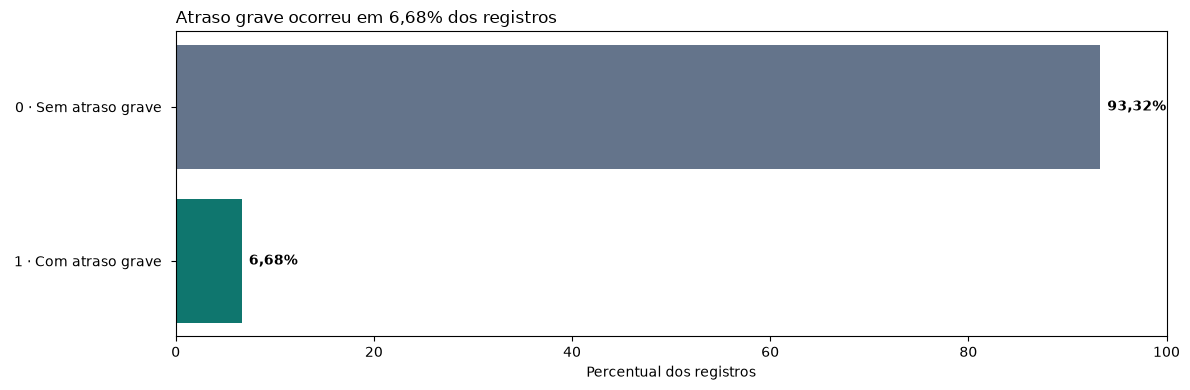

In [9]:
import matplotlib.pyplot as plt

percentuais = distribuicao_alvo.loc[[0, 1], "percentual"]
rotulos = [" 0 · Sem atraso grave ", " 1 · Com atraso grave "]

fig, ax = plt.subplots(figsize=(12, 4))
barras = ax.barh(rotulos, percentuais, color=["#64748b", "#0f766e"])

ax.bar_label(
    barras,
    labels=[f"{valor:.2f}%".replace(".", ",") for valor in percentuais],
    padding=5,
    fontweight="bold",
)
ax.set_xlim(0, 100)
ax.set_xlabel("Percentual dos registros")
ax.set_title("Atraso grave ocorreu em 6,68% dos registros", loc="left")
ax.invert_yaxis()

plt.tight_layout()
plt.show()

Dos 150.000 registros, 10.026 (6,68%) pertencem à classe `1`, que representa atraso grave. Há cerca de 14 registros sem atraso grave para cada registro com atraso grave.

Se um modelo previsse a classe `0` para todos os registros desta base, teria **93,32% de acurácia** e **0% de recall na classe `1`**. Ele acertaria a maioria dos registros e deixaria passar todos os casos de atraso grave.

Por isso, na avaliação dos modelos, vamos acompanhar o **recall da classe `1`**, que mede a proporção dos casos reais de atraso grave que o modelo conseguiu identificar.

## Valores ausentes e relação com a renda

### Panorama de ausências

In [10]:
contagem_ausentes = df.isna().sum().sort_values(ascending=False)

resumo_ausentes = contagem_ausentes.to_frame("registros_ausentes")
resumo_ausentes["percentual"] = (
    contagem_ausentes / len(df) * 100
).round(2)

resumo_ausentes.rename_axis("coluna")

,registros_ausentes,percentual
coluna,,
MonthlyIncome,29731,19.82
NumberOfDependents,3924,2.62
Unnamed: 0,0,0.00
SeriousDlqin2yrs,0,0.00
age,0,0.00
RevolvingUtilizationOfUnsecuredLines,0,0.00
DebtRatio,0,0.00
NumberOfTime30-59DaysPastDueNotWorse,0,0.00
NumberOfOpenCreditLinesAndLoans,0,0.00


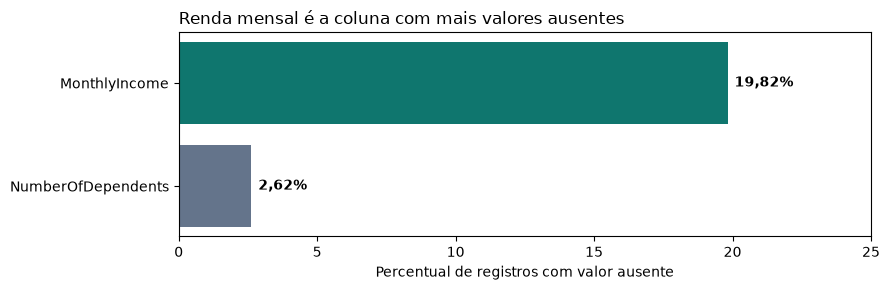

In [11]:
colunas_com_ausentes = resumo_ausentes.loc[
    resumo_ausentes["registros_ausentes"] > 0
]

fig, ax = plt.subplots(figsize=(9, 3))

barras = ax.barh(
    colunas_com_ausentes.index,
    colunas_com_ausentes["percentual"],
    color=["#0f766e", "#64748b"],
)

ax.bar_label(
    barras,
    labels=[
        f"{valor:.2f}%".replace(".", ",")
        for valor in colunas_com_ausentes["percentual"]
    ],
    padding=5,
    fontweight="bold",
)
ax.set_xlim(0, 25)
ax.set_xlabel("Percentual de registros com valor ausente")
ax.set_title("Renda mensal é a coluna com mais valores ausentes", loc="left")
ax.invert_yaxis()

plt.tight_layout()
plt.show()

### Sobreposição de ausências

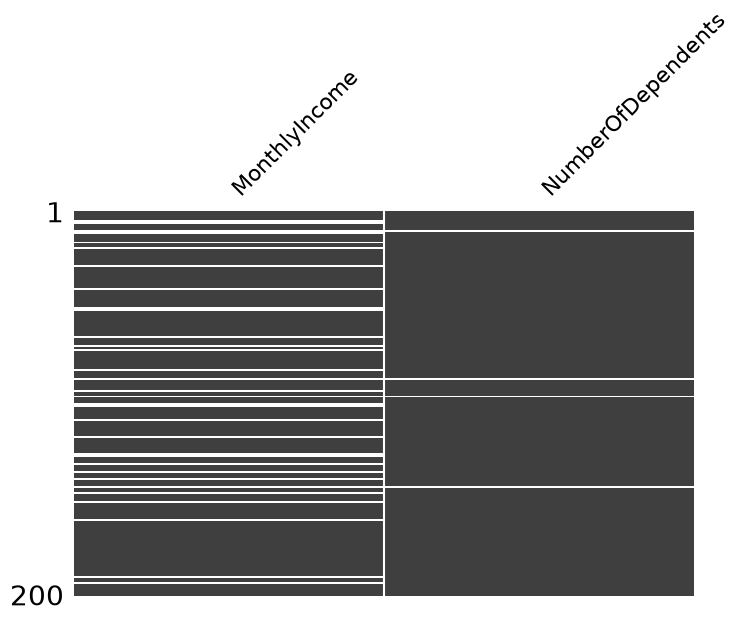

In [12]:
import missingno as msno

colunas = ["MonthlyIncome", "NumberOfDependents"]
amostra_ausencias = df[colunas].sample(n=200, random_state=42).sort_index()

msno.matrix(amostra_ausencias, figsize=(8, 5), sparkline=False)
plt.show()

In [13]:
renda_ausente = df["MonthlyIncome"].isna()
dependentes_ausentes = df["NumberOfDependents"].isna()

cruzamento_ausencias = pd.crosstab(
    renda_ausente,
    dependentes_ausentes,
    rownames=["Renda mensal"],
    colnames=["Número de dependentes"],
    margins=True,
    margins_name="Total",
)

cruzamento_ausencias.rename(
    index={False: "Presente", True: "Ausente"},
    columns={False: "Presente", True: "Ausente"},
)

Número de dependentes,Presente,Ausente,Total
Renda mensal,,,
Presente,120269,0,120269
Ausente,25807,3924,29731
Total,146076,3924,150000


- Entre os registros sem `NumberOfDependents`, **100%** também estão sem `MonthlyIncome` (3.924 de 3.924).
- Entre os registros sem `MonthlyIncome`, **13,20%** também estão sem `NumberOfDependents` (3.924 de 29.731).

A ausência de dependentes está concentrada no grupo sem renda informada. A origem desse padrão permanece em aberto.

### DebtRatio e presença de renda

In [14]:
resumo_debt_ratio = df.groupby(renda_ausente)["DebtRatio"].agg(
    registros="size",
    mediana="median",
    percentil_95=lambda valores: valores.quantile(0.95),
    maximo="max",
)

resumo_debt_ratio.rename(
    index={False: "Renda informada", True: "Renda ausente"}
).rename_axis("Grupo").round(3)

,registros,mediana,percentil_95,maximo
Grupo,,,,
Renda informada,120269,0.296,1.129,61106.5
Renda ausente,29731,1159.000,4902.500,329664.0


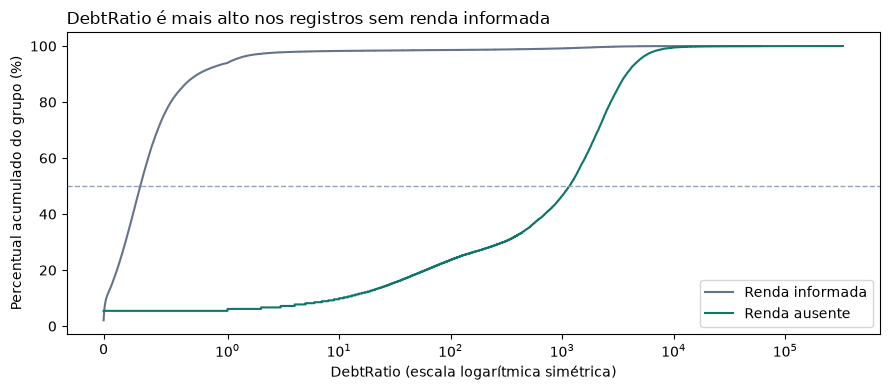

In [15]:
fig, ax = plt.subplots(figsize=(9, 4))

grupos = [
    ("Renda informada", ~renda_ausente, "#64748b"),
    ("Renda ausente", renda_ausente, "#0f766e"),
]

for rotulo, filtro, cor in grupos:
    acumulado = (
        df.loc[filtro, "DebtRatio"]
        .value_counts(normalize=True)
        .sort_index()
        .cumsum()
        .mul(100)
    )

    ax.step(acumulado.index, acumulado, where="post", label=rotulo, color=cor)

ax.set_xscale("symlog", linthresh=1)
ax.axhline(50, color="#94a3b8", linestyle="--", linewidth=1)
ax.set_xlabel("DebtRatio (escala logarítmica simétrica)")
ax.set_ylabel("Percentual acumulado do grupo (%)")
ax.set_title("DebtRatio é mais alto nos registros sem renda informada", loc="left")
ax.legend()

plt.tight_layout()
plt.show()

| Grupo | Registros | Mediana de `DebtRatio` | Percentil 95 |
| --- | ---: | ---: | ---: |
| Renda informada | 120.269 | 0,296 | 1,129 |
| Renda ausente | 29.731 | 1.159 | 4.902,500 |

A separação entre as curvas aparece já na mediana. Portanto, a diferença entre os grupos vai além de alguns valores extremos.

O dicionário define `DebtRatio` como uma razão que usa a renda mensal bruta no denominador. Como a base registra valores de `DebtRatio` mesmo quando a renda está ausente, a forma de cálculo desses casos permanece em aberto. Esse achado orienta a investigação conjunta dos dois campos antes de definir uma regra de tratamento.

### DebtRatio e renda zero

In [16]:
situacao_renda = pd.Series("Renda diferente de zero", index=df.index)
situacao_renda.loc[df["MonthlyIncome"].eq(0)] = "Renda igual a zero"
situacao_renda.loc[renda_ausente] = "Renda ausente"

resumo_debt_ratio_por_renda = df.groupby(situacao_renda)["DebtRatio"].agg(
    registros="size",
    mediana="median",
    percentil_95=lambda valores: valores.quantile(0.95),
    maximo="max",
)

resumo_debt_ratio_por_renda.rename_axis("Situação da renda").round(3)

,registros,mediana,percentil_95,maximo
Situação da renda,,,,
Renda ausente,29731,1159.000,4902.500,329664.0
Renda diferente de zero,118635,0.292,0.982,61106.5
Renda igual a zero,1634,930.000,4896.700,60212.0


Há **1.634 registros** com `MonthlyIncome` igual a zero. Nesse grupo, a mediana de `DebtRatio` é **930**, ante **0,292** nos registros com renda diferente de zero. O percentil 95 é próximo ao observado nos registros sem renda informada.

O dicionário descreve `DebtRatio` como uma razão que usa a renda mensal bruta no denominador. Ainda precisamos esclarecer como os valores foram registrados nos casos de renda zero ou ausente. A análise vai manter essas duas situações identificadas até definirmos uma regra de tratamento.

## Histórico de atrasos e correlações

### Valores 96 e 98 e correlação de Pearson

In [17]:
colunas_atraso = {
    "NumberOfTime30-59DaysPastDueNotWorse": "30 a 59 dias",
    "NumberOfTime60-89DaysPastDueNotWorse": "60 a 89 dias",
    "NumberOfTimes90DaysLate": "90 dias ou mais",
}

atrasos = df[list(colunas_atraso)].rename(columns=colunas_atraso)
tem_96_ou_98 = atrasos.isin([96, 98]).any(axis=1)

print(f"Registros com 96 ou 98 em pelo menos uma coluna: {tem_96_ou_98.sum()}")

atrasos.loc[tem_96_ou_98].value_counts().to_frame("registros")

Registros com 96 ou 98 em pelo menos uma coluna: 269


,,,registros
30 a 59 dias,60 a 89 dias,90 dias ou mais,
98,98,98,264
96,96,96,5


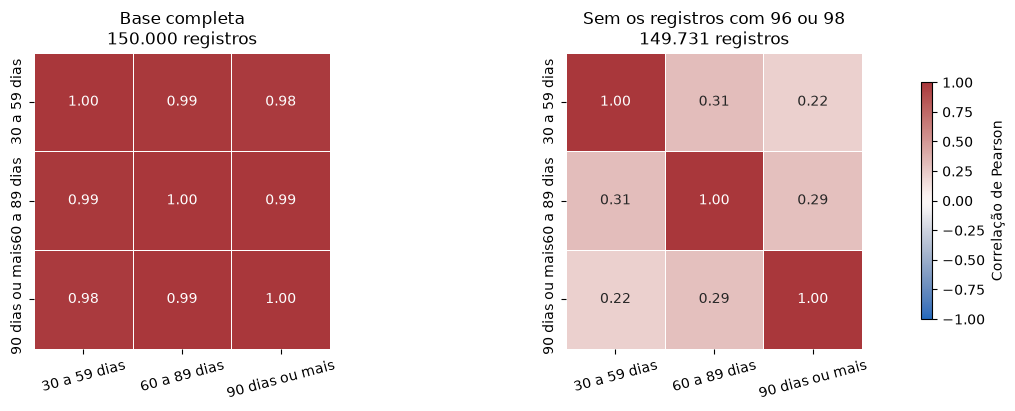

In [18]:
import seaborn as sns

recortes = [
    ("Base completa", atrasos),
    ("Sem os registros com 96 ou 98", atrasos.loc[~tem_96_ou_98]),
]

fig, eixos = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")

for eixo, (titulo, dados) in zip(eixos, recortes):
    correlacao = dados.corr(method="pearson")

    sns.heatmap(
        correlacao,
        annot=True,
        fmt=".2f",
        cmap="vlag",
        vmin=-1,
        vmax=1,
        square=True,
        linewidths=0.5,
        cbar=False,
        ax=eixo,
    )

    total = f"{len(dados):,}".replace(",", ".")
    eixo.set_title(f"{titulo}\n{total} registros")
    eixo.tick_params(axis="x", labelrotation=15)

fig.colorbar(
    eixos[0].collections[0],
    ax=eixos,
    label="Correlação de Pearson",
    shrink=0.8,
)

plt.show()

| Faixas de atraso comparadas | Base completa | Sem os 269 registros |
| --- | ---: | ---: |
| 30 a 59 dias × 60 a 89 dias | 0,99 | 0,31 |
| 30 a 59 dias × 90 dias ou mais | 0,98 | 0,22 |
| 60 a 89 dias × 90 dias ou mais | 0,99 | 0,29 |

Os 269 registros seguem apenas dois padrões: 264 têm `(98, 98, 98)` e 5 têm `(96, 96, 96)`. Quando eles ficam fora do cálculo, as três correlações passam de valores próximos de 1 para valores entre 0,22 e 0,31.

Esse resultado documenta a influência desses registros na correlação de Pearson. O significado de `96` e `98` permanece em aberto. Vamos manter o padrão sinalizado e usar essa evidência na decisão de tratamento.

### Matriz geral de Spearman

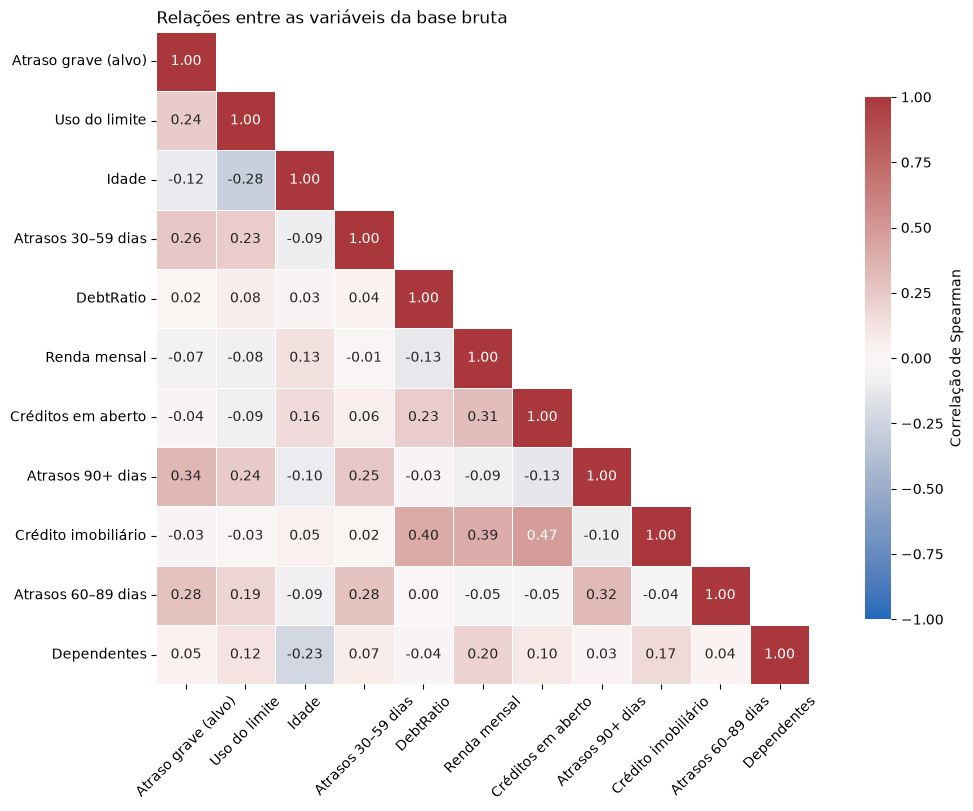

In [19]:
import numpy as np

rotulos_correlacao = {
    "SeriousDlqin2yrs": "Atraso grave (alvo)",
    "RevolvingUtilizationOfUnsecuredLines": "Uso do limite",
    "age": "Idade",
    "NumberOfTime30-59DaysPastDueNotWorse": "Atrasos 30–59 dias",
    "DebtRatio": "DebtRatio",
    "MonthlyIncome": "Renda mensal",
    "NumberOfOpenCreditLinesAndLoans": "Créditos em aberto",
    "NumberOfTimes90DaysLate": "Atrasos 90+ dias",
    "NumberRealEstateLoansOrLines": "Crédito imobiliário",
    "NumberOfTime60-89DaysPastDueNotWorse": "Atrasos 60–89 dias",
    "NumberOfDependents": "Dependentes",
}

correlacao_spearman = (
    df[list(rotulos_correlacao)]
    .rename(columns=rotulos_correlacao)
    .corr(method="spearman")
)

triangulo_superior = np.triu(
    np.ones_like(correlacao_spearman, dtype=bool), k=1
)

fig, ax = plt.subplots(figsize=(11, 8), layout="constrained")

sns.heatmap(
    correlacao_spearman,
    mask=triangulo_superior,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Correlação de Spearman", "shrink": 0.8},
    ax=ax,
)

ax.set_title("Relações entre as variáveis da base bruta", loc="left")
ax.tick_params(axis="x", labelrotation=45)
ax.tick_params(axis="y", labelrotation=0)

plt.show()

- **Entre as variáveis:** crédito imobiliário e créditos em aberto formam o par com a maior correlação fora da diagonal (**+0,47**). Crédito imobiliário e `DebtRatio` vêm em seguida (**+0,40**).
- **Com o alvo:** a contagem de atrasos de 90 dias ou mais apresenta a maior associação com `SeriousDlqin2yrs` (**+0,34**). Em seguida vêm os atrasos de 60 a 89 dias (**+0,28**) e de 30 a 59 dias (**+0,26**).

Antes de usar as contagens de atraso na modelagem, vamos verificar se o histórico estaria disponível no momento da previsão. Essa checagem ajuda a evitar vazamento de dados.

## Validade e valores extremos

### Idades sinalizadas para revisão

In [20]:
idades = df["age"]
idades_para_revisar = idades.loc[(idades < 18) | (idades > 100)]

print(f"Registros sinalizados: {len(idades_para_revisar)}")

idades_para_revisar.value_counts().sort_index().rename_axis("idade").to_frame("registros")

Registros sinalizados: 14


,registros
idade,
0,1
101,3
102,3
103,3
105,1
107,1
109,2


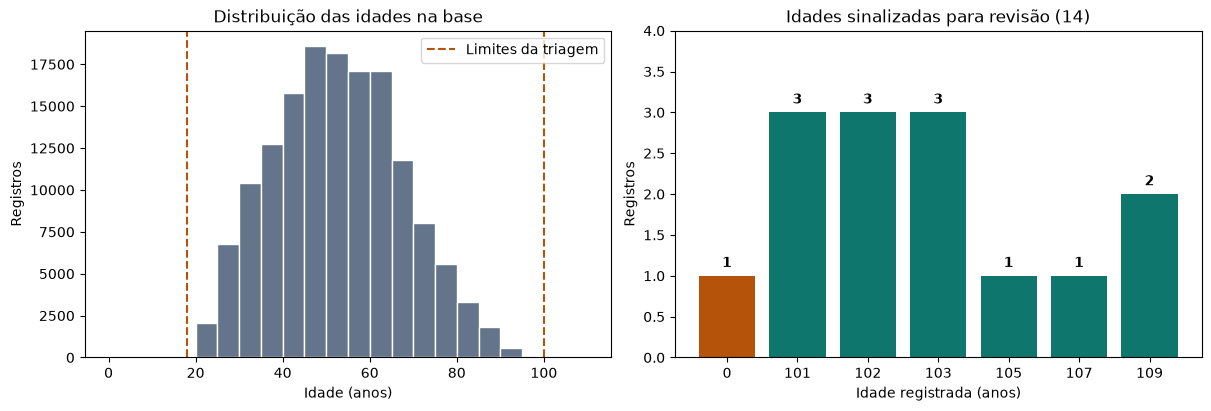

In [21]:
contagem_idades = idades_para_revisar.value_counts().sort_index()
cores = ["#b45309" if idade == 0 else "#0f766e" for idade in contagem_idades.index]

fig, (ax_geral, ax_revisao) = plt.subplots(
    1, 2, figsize=(12, 4), layout="constrained"
)

ax_geral.hist(idades, bins=range(0, 111, 5), color="#64748b", edgecolor="white")
ax_geral.axvline(18, color="#b45309", linestyle="--", label="Limites da triagem")
ax_geral.axvline(100, color="#b45309", linestyle="--")
ax_geral.set_title("Distribuição das idades na base")
ax_geral.set_xlabel("Idade (anos)")
ax_geral.set_ylabel("Registros")
ax_geral.legend()

barras = ax_revisao.bar(
    contagem_idades.index.astype(str),
    contagem_idades.values,
    color=cores,
)
ax_revisao.bar_label(barras, padding=4, fontweight="bold")
ax_revisao.set_ylim(0, contagem_idades.max() + 1)
ax_revisao.set_title(f"Idades sinalizadas para revisão ({len(idades_para_revisar)})")
ax_revisao.set_xlabel("Idade registrada (anos)")
ax_revisao.set_ylabel("Registros")

plt.show()

A análise encontrou 14 registros fora dos limites de triagem de 18 a 100 anos.

- **Idade igual a zero (1 registro).** O valor é incompatível com a idade de um tomador de crédito. O registro deve entrar na revisão de valores inválidos.
- **Idades entre 101 e 109 anos (13 registros).** São idades possíveis. A raridade justifica uma revisão, e qualquer tratamento dependerá de evidência adicional.

As linhas tracejadas do histograma indicam os limites usados na triagem. A base bruta foi preservada.

### Uso do limite acima de 100%

In [22]:
uso_limite = df["RevolvingUtilizationOfUnsecuredLines"]
acima_do_limite = uso_limite.gt(1)

quantidade_acima = acima_do_limite.sum()
percentual_acima = quantidade_acima / len(uso_limite) * 100

print(f"Registros acima de 100% do limite: {quantidade_acima}")
print(f"Percentual da base: {percentual_acima:.2f}%")

uso_limite.describe(percentiles=[0.50, 0.95, 0.99]).loc[
    ["50%", "95%", "99%", "max"]
].round(3).to_frame("uso_do_limite")

Registros acima de 100% do limite: 3321
Percentual da base: 2.21%


,uso_do_limite
50%,0.154
95%,1.000
99%,1.093
max,50708.000


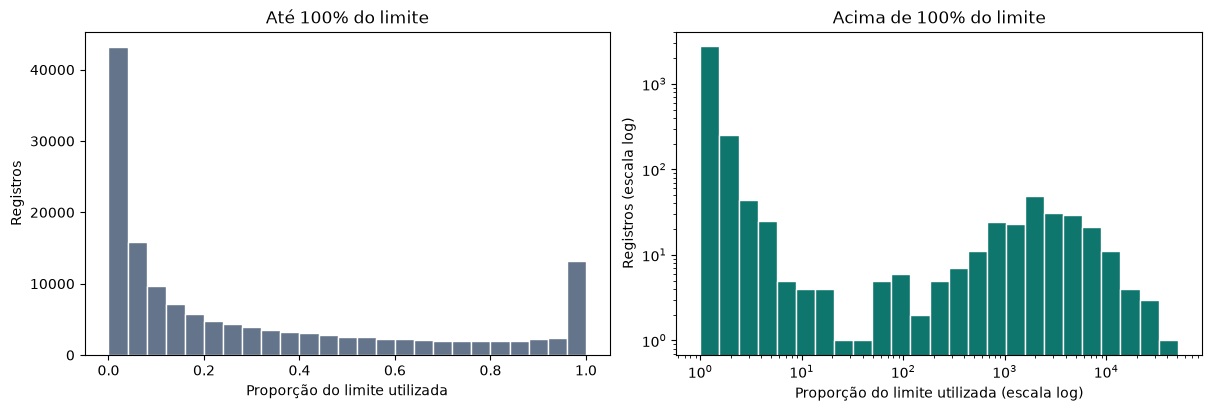

In [23]:
uso_ate_limite = uso_limite.loc[~acima_do_limite]
uso_acima_limite = uso_limite.loc[acima_do_limite]
faixas_cauda = np.geomspace(1, uso_acima_limite.max(), num=26)

fig, (ax_geral, ax_cauda) = plt.subplots(
    1, 2, figsize=(12, 4), layout="constrained"
)

ax_geral.hist(uso_ate_limite, bins=25, color="#64748b", edgecolor="white")
ax_geral.set_title("Até 100% do limite")
ax_geral.set_xlabel("Proporção do limite utilizada")
ax_geral.set_ylabel("Registros")

ax_cauda.hist(
    uso_acima_limite, bins=faixas_cauda,
    color="#0f766e", edgecolor="white", log=True,
)
ax_cauda.set_xscale("log")
ax_cauda.set_title("Acima de 100% do limite")
ax_cauda.set_xlabel("Proporção do limite utilizada (escala log)")
ax_cauda.set_ylabel("Registros (escala log)")

plt.show()

In [24]:
faixas_uso = pd.cut(
    uso_acima_limite,
    bins=[1, 10, 100, 1_000, np.inf],
    labels=[
        "Acima de 1 até menos de 10×",
        "De 10 até menos de 100×",
        "De 100 até menos de 1.000×",
        "1.000× ou mais",
    ],
    right=False,
)

resumo_cauda = faixas_uso.value_counts(sort=False).to_frame("registros")
resumo_cauda["percentual_do_grupo"] = (
    resumo_cauda["registros"] / len(uso_acima_limite) * 100
).round(2)

resumo_cauda.rename_axis("Faixa de uso do limite")

,registros,percentual_do_grupo
Faixa de uso do limite,,
Acima de 1 até menos de 10×,3080,92.74
De 10 até menos de 100×,18,0.54
De 100 até menos de 1.000×,51,1.54
1.000× ou mais,172,5.18


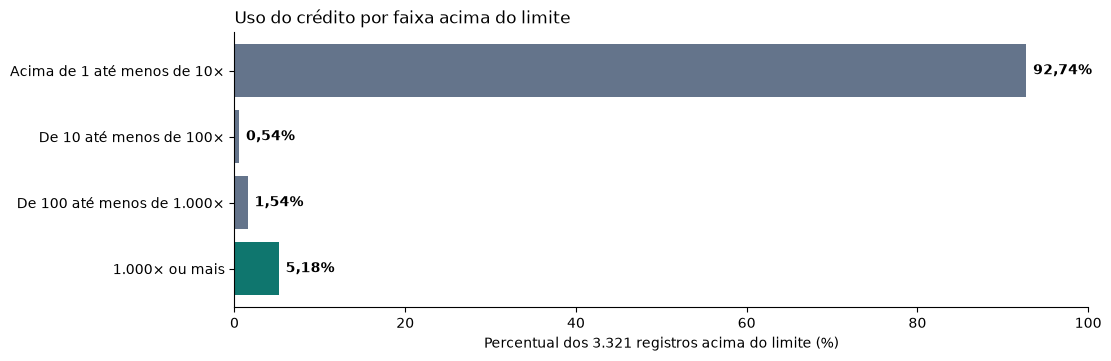

In [25]:
percentuais_faixas = resumo_cauda["percentual_do_grupo"]

fig, ax = plt.subplots(figsize=(11, 3.5), layout="constrained")

barras = ax.barh(
    resumo_cauda.index.astype(str),
    percentuais_faixas,
    color=["#64748b", "#64748b", "#64748b", "#0f766e"],
)

ax.bar_label(
    barras,
    labels=[f"{valor:.2f}%".replace(".", ",") for valor in percentuais_faixas],
    padding=5,
    fontweight="bold",
)
ax.set_xlim(0, 100)
ax.set_xlabel("Percentual dos 3.321 registros acima do limite (%)")
ax.set_title("Uso do crédito por faixa acima do limite", loc="left")
ax.invert_yaxis()
ax.spines[["top", "right"]].set_visible(False)

plt.show()

A coluna `RevolvingUtilizationOfUnsecuredLines` tem 3.321 registros acima de `1`, o equivalente a 2,21% da base. A mediana é `0,154`, o percentil 99 é `1,093` e o máximo registrado é `50.708`.

Entre os registros acima do limite, 3.080 estão abaixo de `10` e 172 chegam a `1.000` ou mais. Para a revisão de qualidade, vale examinar essa faixa extrema separadamente. O valor `1` foi usado como ponto de triagem. A regra de tratamento será definida na pré-modelagem.

## Registros repetidos e desfechos diferentes

In [26]:
dados_sem_numeracao = df.drop(columns="Unnamed: 0")

linhas_em_grupos_repetidos = dados_sem_numeracao.duplicated(keep=False)
repeticoes_apos_a_primeira = dados_sem_numeracao.duplicated(keep="first")

print(f"Linhas que fazem parte de grupos repetidos: {linhas_em_grupos_repetidos.sum()}")
print(f"Repetições além da primeira ocorrência: {repeticoes_apos_a_primeira.sum()}")

Linhas que fazem parte de grupos repetidos: 960
Repetições além da primeira ocorrência: 609


In [27]:
colunas_perfil = dados_sem_numeracao.columns.drop("SeriousDlqin2yrs").tolist()

resumo_perfis = dados_sem_numeracao.groupby(
    colunas_perfil, dropna=False
)["SeriousDlqin2yrs"].agg(
    registros="size",
    classes_distintas="nunique",
)

perfis_com_alvos_distintos = resumo_perfis.loc[
    resumo_perfis["classes_distintas"] > 1
]

print(f"Perfis com as duas classes do alvo: {len(perfis_com_alvos_distintos)}")
print(f"Registros nesses perfis: {perfis_com_alvos_distintos['registros'].sum()}")

Perfis com as duas classes do alvo: 37
Registros nesses perfis: 145


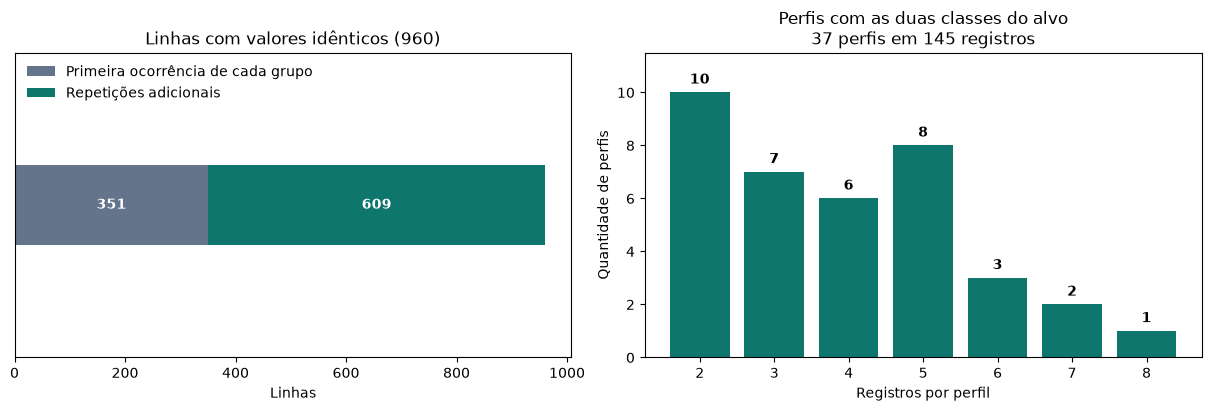

In [28]:
total_linhas_repetidas = int(linhas_em_grupos_repetidos.sum())
repeticoes_adicionais = int(repeticoes_apos_a_primeira.sum())
primeiras_ocorrencias = total_linhas_repetidas - repeticoes_adicionais

tamanhos_perfis = (
    perfis_com_alvos_distintos["registros"].value_counts().sort_index()
)
total_registros_perfis = int(perfis_com_alvos_distintos["registros"].sum())

fig, (ax_linhas, ax_perfis) = plt.subplots(
    1, 2, figsize=(12, 4), layout="constrained"
)

primeiras = ax_linhas.barh(
    0, primeiras_ocorrencias, height=0.45, color="#64748b",
    label="Primeira ocorrência de cada grupo",
)
adicionais = ax_linhas.barh(
    0, repeticoes_adicionais, left=primeiras_ocorrencias,
    height=0.45, color="#0f766e", label="Repetições adicionais",
)

for barras in (primeiras, adicionais):
    ax_linhas.bar_label(
        barras, label_type="center", color="white", fontweight="bold"
    )

ax_linhas.set_title(f"Linhas com valores idênticos ({total_linhas_repetidas})")
ax_linhas.set_xlabel("Linhas")
ax_linhas.set_yticks([])
ax_linhas.set_ylim(-0.85, 0.85)
ax_linhas.legend(loc="upper left", frameon=False)

barras_perfis = ax_perfis.bar(
    tamanhos_perfis.index.astype(str),
    tamanhos_perfis.values,
    color="#0f766e",
)
ax_perfis.bar_label(barras_perfis, padding=4, fontweight="bold")
ax_perfis.set_ylim(0, tamanhos_perfis.max() * 1.15)
ax_perfis.set_title(
    f"Perfis com as duas classes do alvo\n"
    f"{len(perfis_com_alvos_distintos)} perfis em {total_registros_perfis} registros"
)
ax_perfis.set_xlabel("Registros por perfil")
ax_perfis.set_ylabel("Quantidade de perfis")

plt.show()

- **Incluindo o alvo:** 960 linhas pertencem a 351 grupos com valores idênticos. Dessas linhas, 609 são ocorrências além da primeira de cada grupo.
- **Considerando apenas as variáveis de entrada:** 37 perfis, que somam 145 registros, aparecem tanto com atraso grave (`1`) quanto sem atraso grave (`0`).

A comparação verifica igualdade entre os valores disponíveis. Como `Unnamed: 0` é uma numeração de linhas, a identidade dos tomadores permanece em aberto.

Vamos preservar esses registros na base bruta. Na pré-modelagem, vamos verificar se perfis idênticos aparecem nos dois lados da divisão treino/teste e avaliar uma divisão por grupos para mantê-los juntos.

## Resumo dos achados e implicações para o pipeline

| Achado | Evidência na base | Implicação para o pipeline |
| --- | --- | --- |
| Alvo desbalanceado | 6,68% dos registros têm atraso grave. | Acompanhar o recall da classe `1` e a matriz de confusão na avaliação. |
| Ausências concentradas | Faltam 29.731 valores de renda e 3.924 de dependentes. Todos os registros sem dependentes também estão sem renda. | Definir tolerâncias de ausência por coluna no contrato de entrada. |
| `DebtRatio` associado à situação da renda | A mediana foi 0,292 com renda diferente de zero, 930 com renda zero e 1.159 com renda ausente. | Distinguir renda zero de renda ausente e investigar os dois campos em conjunto antes de transformar a razão. |
| Valores `96` e `98` nas contagens de atraso | Em 269 registros, o mesmo valor aparece nas três colunas. Ao retirá-los do cálculo, as correlações de Pearson entre as contagens caem de 0,98–0,99 para 0,22–0,31. | Sinalizar o padrão e documentar a regra de tratamento, pois o significado dos valores permanece em aberto. |
| Idade e uso do limite fora do padrão | A base contém um registro com idade zero, 13 acima de 100 anos e 172 registros com uso igual ou superior a 1.000 vezes o limite. | Tratar idade zero como inválida e revisar separadamente as idades raras e os valores extremos de utilização. |
| Perfis de entrada com desfechos diferentes | Há 37 perfis que aparecem com as duas classes do alvo, somando 145 registros. | Verificar se perfis idênticos aparecem nos dois lados da divisão treino/teste e avaliar uma divisão por grupos. |

A base bruta foi preservada. Os achados orientam as próximas decisões de validação e tratamento.